# Milestone 03 - Baseline Models for Out-of-School Prediction (ASER 2025, Pakistan)

**Research question.** Among children aged 5-16 in Pakistan, can we predict whether a child is out of school
(never enrolled or dropped out) from household poverty indicators, legal identity documentation, disability status
and demographic / geographic characteristics - and does the model work equally well for girls, children with
disabilities and rural children? (SDG 4.1 access, SDG 4.5 disparities.)

**What this notebook does.** It implements the Milestone 3 brief end to end: a naive benchmark plus three baseline
learners (logistic regression, decision tree, random forest), a leakage-free district-grouped stratified cross-validation framework
with hyperparameter tuning, the full metric set with confusion matrices, an asymmetric error-cost analysis with
threshold shifting, feature-importance drivers read against the five Milestone 2 hypotheses, and the roadmap for
Milestone 4. All modelling code lives in `src/` and is imported here so the notebook stays readable; `src/run_all.py`
reproduces every table and figure from the command line.

**Data.** `data/aser2025_training.csv` (161,803 children x 17 columns) built in Milestone 2. Column roles come from
`data/feature_manifest.json`; nothing is hard-coded.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)

sys.path.insert(0, str(Path("src").resolve()))
import config as C
from data import load_training, split_xy, describe_split, load_subgroup_counts, load_attrition, province_of
from cv import make_holdout, make_inner_cv, tune, cv_table, fold_scores
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
import models as M, evaluate as ev, importance as imp, plots

print("Target:", C.TARGET)
print("Features (%d):" % len(C.FEATURES), C.FEATURES)
print("ID / CV group / weight:", C.ID_COL, "/", C.GROUP_COL, "/", C.WEIGHT_COL)

Target: out_of_school
Features (13): ['age', 'female', 'urban', 'female_x_urban', 'bform', 'any_disability', 'assets_n', 'digital_n', 'house', 'province_Sindh', 'province_Khyber Pakhtuknkhwa', 'province_Balochistan', 'province_Islamabad Capital Territory']
ID / CV group / weight: cid / district / weight


## 1. Data and integrity checks

`load_training()` asserts the properties documented in `encoding_log.txt`: 161,803 rows, zero missing values in the
features and target, unique child ids, and province dummies that never overlap (Punjab is the reference category).
The attrition table shows how the raw 183,854 ASER records became this analysis sample.

In [2]:
df = load_training()
X, y, groups, w = split_xy(df)
print(f"{df.shape[0]:,} children x {df.shape[1]} columns; {df[C.GROUP_COL].nunique()} districts")
print(f"out_of_school = 1: {y.sum():,} ({y.mean():.1%} unweighted, {np.average(y, weights=w):.1%} survey-weighted)")
display(load_attrition())
display(df[C.FEATURES + [C.TARGET]].describe().T[["mean", "std", "min", "max"]])

161,803 children x 17 columns; 138 districts
out_of_school = 1: 21,288 (13.2% unweighted, 9.3% survey-weighted)


,step,rows
0,raw file,183854
1,after dropping exact duplicate rows,183854
2,age 5-16 (missing age dropped),161803
3,valid enrolment status (C4),161803
4,complete cases on full feature set (separate f...,161803


,mean,std,min,max
age,9.4720,3.2048,5.0,16.0
female,0.3840,0.4864,0.0,1.0
urban,0.3739,0.4838,0.0,1.0
female_x_urban,0.1471,0.3542,0.0,1.0
bform,0.5821,0.4932,0.0,1.0
any_disability,0.1277,0.3338,0.0,1.0
assets_n,3.1471,1.5874,0.0,8.0
digital_n,2.5405,1.6136,0.0,5.0
house,2.0275,0.8119,1.0,3.0
province_Sindh,0.2726,0.4453,0.0,1.0


**Interpretation.** The target is imbalanced (13.2% positive). A classifier that always predicts "enrolled" scores
~87% accuracy while finding no out-of-school child at all, so accuracy is not a useful headline metric here; we lean
on recall, F1, ROC-AUC and PR-AUC. All predictors are binary or small-integer ordinal; province is already one-hot
encoded, so no further encoding or scaling is applied outside the model pipelines (the logistic pipeline standardises
inside each fold).

## 2. Partitioning: district-grouped, target-stratified hold-out

Many children share a district, and districts differ strongly in enrolment. A plain random split would let the
model see children from the same district on both sides and over-state performance. We therefore use
`StratifiedGroupKFold(5)` grouped by `district` and stratified on the target: one fold (~20% of children, whole
districts) is the untouched hold-out test set; the remaining ~80% is used for tuning with a second
`StratifiedGroupKFold(5)` (the *inner* CV). The assertion below proves that no district appears on both sides.

In [3]:
train_idx, test_idx = make_holdout(y, groups)       # raises if a district leaks across the split
split_desc = describe_split(df, train_idx, test_idx)
display(split_desc)
Xtr, Xte = X.iloc[train_idx], X.iloc[test_idx]
ytr, yte = y[train_idx], y[test_idx]
gtr = groups[train_idx]; wte = w[test_idx]
df_te = df.iloc[test_idx].reset_index(drop=True)
print("districts overlapping:", len(set(groups[train_idx]) & set(groups[test_idx])))
print("inner CV:", make_inner_cv())

,partition,rows,share_of_rows,positives,prevalence,districts
0,train,129287,0.799,17220,0.1332,109
1,test,32516,0.201,4068,0.1251,29


districts overlapping: 0
inner CV: StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)


## 3. Models and justification

| Model | Why it is a sensible baseline here |
|---|---|
| **Majority-class benchmark** (`DummyClassifier(most_frequent)`) | Fixes the floor: predicts "enrolled" for everyone. Shows how misleading raw accuracy is at 13% prevalence. |
| **Logistic regression** (`StandardScaler` -> L2-penalised LR) | Our hypotheses H1-H4 are statements about the *direction and size* of individual effects (assets, B-form, disability, gender x area). Logistic coefficients give odds ratios with confidence intervals that answer them directly. Features are binary / ordinal, so a linear-in-log-odds model is a natural first fit. Tuned: regularisation strength `C`, class weighting. |
| **Decision tree** (CART, Gini) | Captures non-linear thresholds (e.g. asset counts) and interactions (H4) without hand-specification, is fully interpretable through its splits and Gini importance, and is cheap on 161k rows. Tuned: `max_depth`, `min_samples_leaf`, class weighting. |
| **Random forest** (200 bagged trees, `sqrt` features per split) | A single tree is unstable and stops short of the best ranking; averaging many de-correlated trees (bootstrap re-samples + random feature subsets) fixes both while keeping Gini/permutation importance. A distinct algorithm from the single tree and the bridge to Milestone 4's stronger models. Tuned: `max_depth`, `min_samples_leaf`, class weighting. |

Both learners are tuned with `GridSearchCV` on the district-grouped inner folds, refitting on ROC-AUC
(threshold-free, imbalance-robust); recall, precision, F1, accuracy and PR-AUC are recorded per fold as well.

In [4]:
naive = M.build_naive().fit(Xtr, ytr)
probas = {"naive": naive.predict_proba(Xte)[:, 1]}

gs_lr = tune(M.build_logreg(), M.LOGREG_GRID, Xtr, ytr, gtr)
probas["logreg"] = gs_lr.predict_proba(Xte)[:, 1]
print("Logistic regression - best:", gs_lr.best_params_, f"CV ROC-AUC = {gs_lr.best_score_:.4f}")
display(cv_table(gs_lr)[["C", "class_weight", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_recall", "mean_test_f1", "mean_test_average_precision"]])

Logistic regression - best: {'clf__C': 0.001, 'clf__class_weight': 'balanced'} CV ROC-AUC = 0.7357


,C,class_weight,mean_test_roc_auc,std_test_roc_auc,mean_test_recall,mean_test_f1,mean_test_average_precision
0,0.001,balanced,0.7357,0.0416,0.7019,0.3658,0.2657
1,0.010,balanced,0.7353,0.0418,0.7027,0.3659,0.2654
2,0.100,balanced,0.7352,0.0418,0.7025,0.3659,0.2654
3,1.000,balanced,0.7352,0.0418,0.7026,0.3659,0.2654
4,10.000,balanced,0.7352,0.0418,0.7026,0.3659,0.2654
5,0.001,NaN,0.7330,0.0415,0.0074,0.0143,0.2640
6,0.010,NaN,0.7317,0.0414,0.0125,0.0237,0.2631
7,0.100,NaN,0.7316,0.0415,0.0135,0.0256,0.2629
8,1.000,NaN,0.7316,0.0415,0.0135,0.0256,0.2629
9,10.000,NaN,0.7316,0.0415,0.0135,0.0256,0.2629


In [5]:
gs_tree = tune(M.build_tree(), M.TREE_GRID, Xtr, ytr, gtr)
probas["tree"] = gs_tree.predict_proba(Xte)[:, 1]
print("Decision tree - best:", gs_tree.best_params_, f"CV ROC-AUC = {gs_tree.best_score_:.4f}")
display(cv_table(gs_tree)[["max_depth", "min_samples_leaf", "class_weight", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_recall", "mean_test_f1"]].head(12))

Decision tree - best: {'clf__class_weight': None, 'clf__max_depth': 10, 'clf__min_samples_leaf': 200} CV ROC-AUC = 0.7439


,max_depth,min_samples_leaf,class_weight,mean_test_roc_auc,std_test_roc_auc,mean_test_recall,mean_test_f1
0,10,200,NaN,0.7439,0.0457,0.0677,0.1122
1,7,200,NaN,0.7410,0.0451,0.0397,0.0684
2,None,200,NaN,0.7402,0.0426,0.0658,0.1092
3,15,200,NaN,0.7402,0.0429,0.0658,0.1092
4,7,50,NaN,0.7402,0.0439,0.0419,0.0712
5,7,1000,NaN,0.7384,0.0512,0.0410,0.0701
6,7,1,NaN,0.7380,0.0453,0.0453,0.0764
7,10,200,balanced,0.7365,0.0475,0.6731,0.3663
8,10,1000,NaN,0.7362,0.0492,0.0473,0.0788
9,15,1000,NaN,0.7362,0.0491,0.0473,0.0788


In [6]:
gs_rf = tune(M.build_rf(), M.RF_GRID, Xtr, ytr, gtr)     # ~3-4 minutes: 18 settings x 5 folds x 200 trees
probas["rf"] = gs_rf.predict_proba(Xte)[:, 1]
print("Random forest - best:", gs_rf.best_params_, f"CV ROC-AUC = {gs_rf.best_score_:.4f}")
display(cv_table(gs_rf)[["max_depth", "min_samples_leaf", "class_weight", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_recall", "mean_test_f1"]].head(10))

Random forest - best: {'clf__class_weight': None, 'clf__max_depth': 12, 'clf__min_samples_leaf': 20} CV ROC-AUC = 0.7549


,max_depth,min_samples_leaf,class_weight,mean_test_roc_auc,std_test_roc_auc,mean_test_recall,mean_test_f1
0,12,20,NaN,0.7549,0.0402,0.0243,0.0438
1,12,100,balanced_subsample,0.7529,0.0441,0.6849,0.3826
2,12,100,NaN,0.7527,0.0425,0.0100,0.0191
3,12,20,balanced_subsample,0.7526,0.0422,0.6321,0.3836
4,None,100,NaN,0.7525,0.0422,0.0100,0.0190
5,8,20,NaN,0.7525,0.0426,0.0080,0.0152
6,None,100,balanced_subsample,0.7525,0.0432,0.6868,0.3826
7,None,20,NaN,0.7517,0.0392,0.0302,0.0541
8,8,100,NaN,0.7514,0.0437,0.0059,0.0115
9,8,100,balanced_subsample,0.7499,0.0448,0.6953,0.3779


**Interpretation of the tuning.** (In the grid tables, `recall`, `f1` and `accuracy` are measured at the default 0.5
threshold; ROC-AUC and average precision are threshold-free.) For logistic regression the strongest regularisation
(`C = 0.001`) with balanced class weights wins on AUC; the ranking is flat across `C` (the coefficients are already
well-determined with 129k rows), while balancing matters for recall at the default threshold. For the tree, moderate
depth (10) with a large minimum leaf (200 children) is best - deeper, unconstrained trees over-fit district
idiosyncrasies and lose AUC on unseen districts. Because the refit criterion is ROC-AUC, the selected tree carries *no*
class weighting, and at the default 0.5 cut-off it flags almost nobody (recall ~0.07 in CV, ~0.04 on hold-out): almost no
leaf reaches a 50% out-of-school share. The same holds for the random forest (best: depth 12, leaf >= 20, no class
weights, CV AUC 0.755 - the highest of the three; default-threshold recall ~0.02-0.04). That is not a defect of the
tree models - it is why the operating threshold is set separately, on training data only, in section 6. Fold-to-fold standard deviations of ~0.05 AUC show how much
performance varies between groups of districts, which is exactly the variance a random split would have hidden.

## 4. Hypothesis H5 - do poverty, B-form, disability and the controls add predictive value?

Same inner folds, same learner, two feature sets: the bare demographic model (`age, female, urban`) versus the
full 13-feature model. The paired per-fold AUC difference is tested with a paired t-test.

,fold,auc_demographic,auc_full,gain
0,1,0.5855,0.7238,0.1383
1,2,0.6464,0.7177,0.0713
2,3,0.5462,0.8163,0.2702
3,4,0.5458,0.6960,0.1502
4,5,0.6043,0.7248,0.1205


mean AUC demographic = 0.5856 (sd 0.0424); full = 0.7357 (sd 0.0465)
mean gain = +0.1501; paired t = 4.56, p = 0.0103
hold-out AUC: demographic 0.5470 vs full 0.6741


hold-out gain +0.1271 AUC, 95% district-bootstrap CI [+0.0778, +0.1728] (29 districts, 1000 draws, positive in 100%)


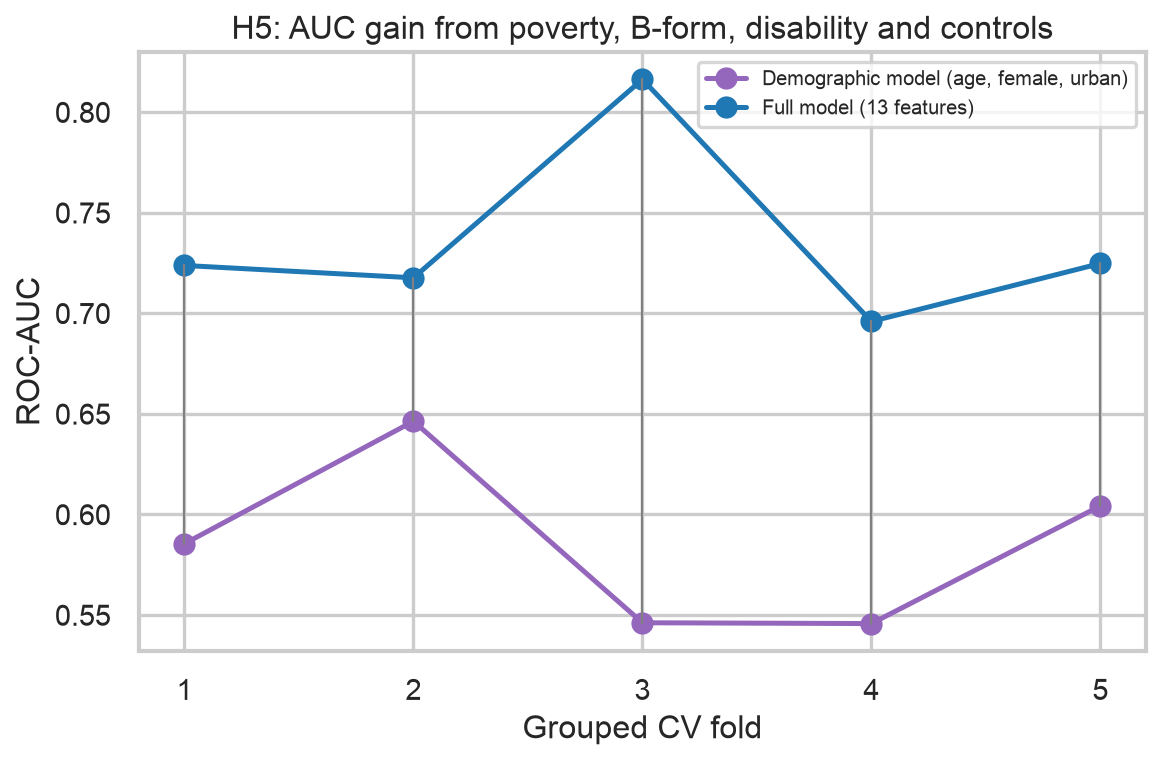

In [7]:
from scipy import stats
gs_demo = tune(M.build_logreg(), M.LOGREG_GRID, Xtr[C.DEMO_FEATURES], ytr, gtr)
probas["logreg_demo"] = gs_demo.predict_proba(Xte[C.DEMO_FEATURES])[:, 1]
auc_demo, auc_full = fold_scores(gs_demo, "roc_auc"), fold_scores(gs_lr, "roc_auc")
t, p = stats.ttest_rel(auc_full, auc_demo)
h5 = pd.DataFrame({"fold": range(1, 6), "auc_demographic": auc_demo, "auc_full": auc_full, "gain": auc_full - auc_demo})
display(h5)
print(f"mean AUC demographic = {auc_demo.mean():.4f} (sd {auc_demo.std(ddof=1):.4f}); full = {auc_full.mean():.4f} (sd {auc_full.std(ddof=1):.4f})")
print(f"mean gain = {(auc_full-auc_demo).mean():+.4f}; paired t = {t:.2f}, p = {p:.4f}")
print(f"hold-out AUC: demographic {ev.metrics(yte, probas['logreg_demo'])['roc_auc']:.4f} vs full {ev.metrics(yte, probas['logreg'])['roc_auc']:.4f}")
# five folds are a thin basis for a t-test -> district-cluster bootstrap of the hold-out AUC gain
bs = ev.cluster_bootstrap_auc_diff(yte, probas["logreg_demo"], probas["logreg"], groups[test_idx])
print(f"hold-out gain {bs['diff_point']:+.4f} AUC, 95% district-bootstrap CI [{bs['ci_low']:+.4f}, {bs['ci_high']:+.4f}] "
      f"({bs['n_clusters']} districts, {bs['n_boot']} draws, positive in {bs['share_positive']:.0%})")
display(Image(plots.h5_auc_folds(auc_demo, auc_full)))

**H5 verdict.** The full model beats the demographic model in every fold (gain ~ +0.15 AUC, paired t-test p ~ 0.01)
and on the hold-out districts (+0.13). Five folds are a thin basis for a p-value, so the hold-out gain is also
bootstrapped by resampling the 29 held-out *districts* with replacement: the 95% interval (~ +0.08 to +0.17) excludes
zero comfortably. Age, sex and area alone are close to chance (AUC ~ 0.59): *who is out of school is far better
explained by household circumstances than by demographics*. We reject H0 for H5.

## 5. Hold-out performance at the default threshold (0.5)

Metrics on the 32,516 children in the held-out districts. A survey-weighted version (ASER sampling weights) is
reported as a robustness check; the unweighted numbers are the primary ones.

,model,weighted,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,flagged_rate
0,Majority-class baseline,no,0.8749,NaN,0.0000,1.0000,0.0000,0.5000,0.1251,0.0000
1,Majority-class baseline,yes,0.8514,NaN,0.0000,1.0000,0.0000,0.5000,0.1486,0.0000
2,"Logistic regression (age, female, urban)",no,0.4664,0.1328,0.5902,0.4487,0.2168,0.5470,0.1476,0.5562
3,"Logistic regression (age, female, urban)",yes,0.4196,0.1458,0.5980,0.3885,0.2344,0.5118,0.1567,0.6095
4,Logistic regression,no,0.6199,0.1918,0.6342,0.6179,0.2946,0.6741,0.2142,0.4136
5,Logistic regression,yes,0.7075,0.2627,0.5361,0.7374,0.3526,0.7133,0.2562,0.3032
6,Decision tree,no,0.8666,0.2816,0.0428,0.9844,0.0743,0.7112,0.2357,0.0190
7,Decision tree,yes,0.8474,0.3286,0.0255,0.9909,0.0474,0.7486,0.3079,0.0115
8,Random forest,no,0.8736,0.4392,0.0364,0.9934,0.0672,0.7247,0.2537,0.0104
9,Random forest,yes,0.8508,0.4697,0.0307,0.9940,0.0576,0.7550,0.3196,0.0097


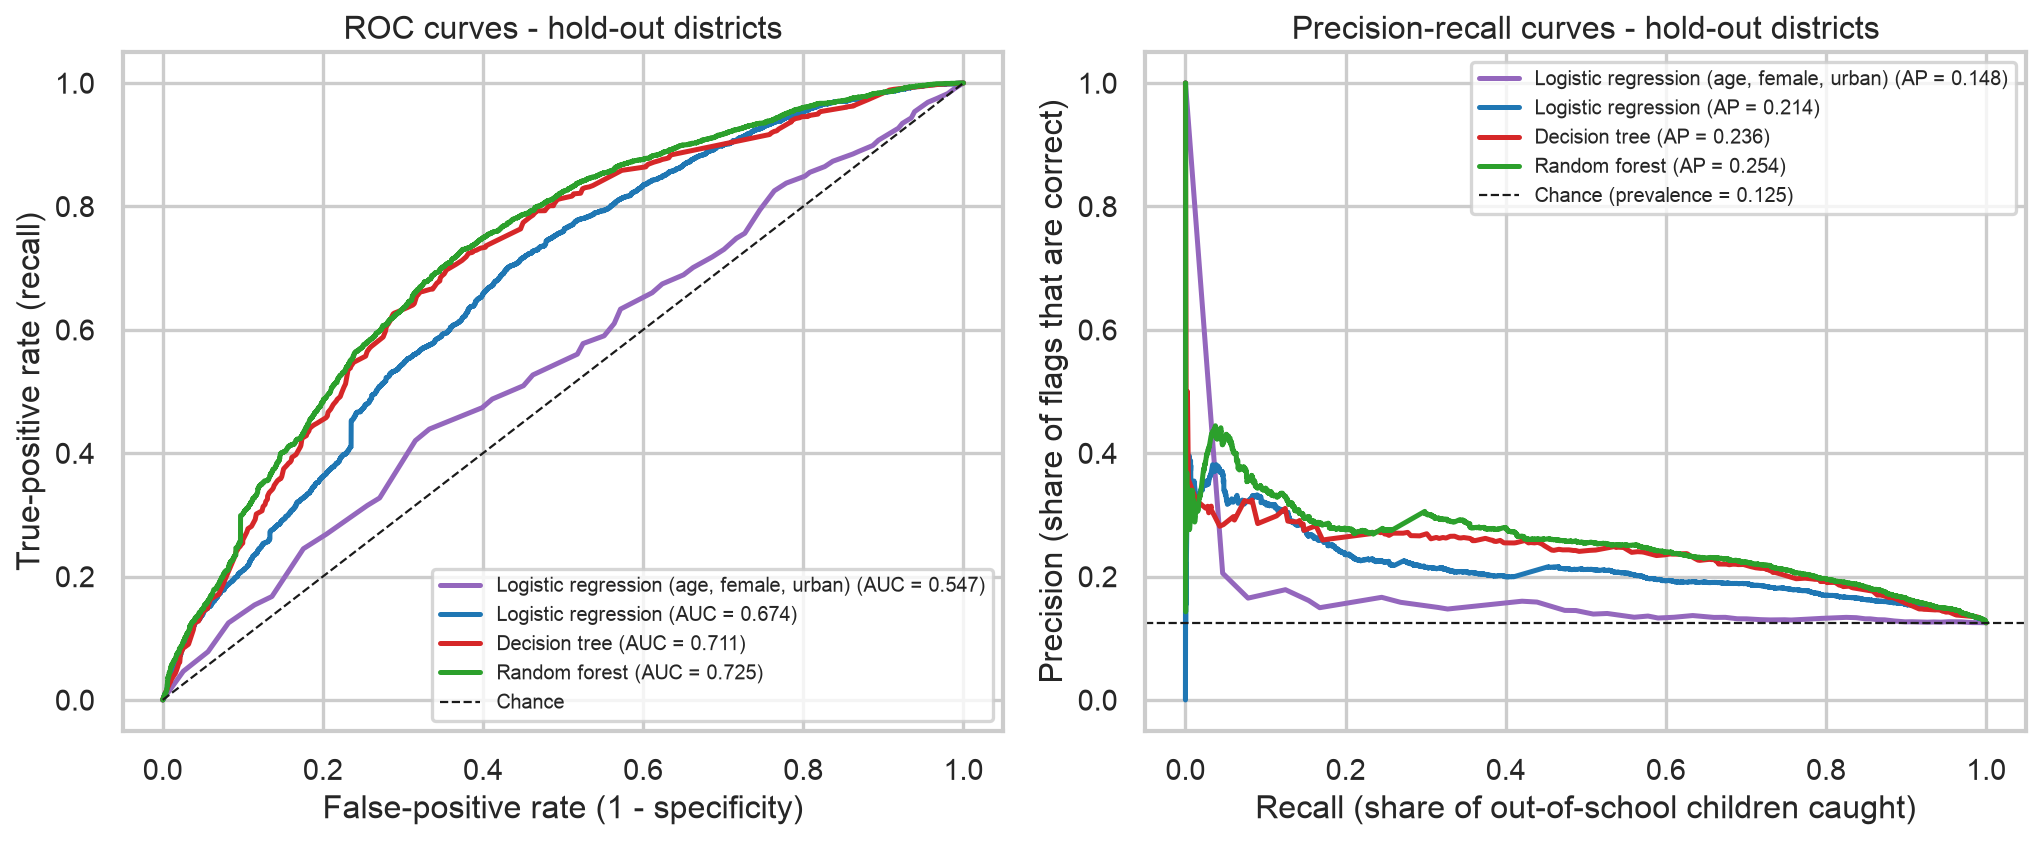

In [8]:
rows = []
for key in ("naive", "logreg_demo", *M.MODELS):
    rows.append({"model": M.MODEL_NAMES[key], "weighted": "no", **ev.metrics(yte, probas[key], 0.5)})
    rows.append({"model": M.MODEL_NAMES[key], "weighted": "yes", **ev.metrics(yte, probas[key], 0.5, w=wte)})
holdout = pd.DataFrame(rows)
cols = ["model", "weighted", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "flagged_rate"]
display(holdout[cols])
display(Image(plots.roc_pr_curves(yte, {k: probas[k] for k in ("logreg_demo", *M.MODELS)}, M.MODEL_NAMES, float(yte.mean()))))

**Interpretation.** The majority-class benchmark reaches 87.5% accuracy with zero recall - every out-of-school
child is missed. The balanced logistic regression trades accuracy (62%) for recall (63%) at the default cut-off. The
tree has better ranking quality (ROC-AUC 0.71, PR-AUC 0.24) and the random forest the best (ROC-AUC 0.72, PR-AUC
0.25), but both were tuned without class weights, so their default-threshold recall is only ~4%: almost no leaf reaches
a 50% out-of-school share. This is the clearest
demonstration that **the threshold, not the learner, decides who gets flagged** - which is the subject of the next
section. Applying the ASER sampling weights moves the metrics in *different directions for different models*: ROC-AUC
rises from 0.674 to 0.713 for the full logistic model, from 0.711 to 0.749 for the tree and from 0.725 to 0.755 for the
forest, but falls from 0.547 to 0.512 for the demographic-only model. The weights up-weight households the sample under-represents - predominantly
poorer, rural ones - where the household features carry most of their signal and where age, sex and area alone
separate least. Population-level statements should quote the weighted figures. Hold-out AUCs are ~0.03-0.06 below the
CV means: the held-out districts are a harder group, within the fold-to-fold spread seen in CV.

## 6. Confusion matrices and asymmetric error costs

*Policy reading of the two error types.*
- **False negative** - the model says "in school" but the child is out of school: a child who needs an enrolment /
  outreach intervention is never visited. This is the costly error for an education-access programme.
- **False positive** - the model says "out of school" but the child is enrolled: an outreach visit or a stipend slot is
  spent on a child who did not need it; wasteful, but recoverable.

We make this explicit by assigning a false negative a cost of *r* false positives (r = 1, 3, 5, 10), sweeping the
classification threshold from 0.05 to 0.95 and reporting the expected cost per 1,000 children screened. The
recommended operating point uses r = 5.

**The threshold is chosen without looking at the hold-out.** A threshold is a model setting like `C` or `max_depth`;
picking it on the test set and then reporting test performance at that value would be circular. So each tuned pipeline
is re-fitted on the same five district-grouped training folds, out-of-fold probabilities are collected for every
training child (`cross_val_predict`), the cost curve is swept on those, and only the chosen threshold is then applied -
once - to the hold-out districts. For transparency the tables also show what the hold-out's *own* optimum would have
been, so the size of the flattery that selection-on-test would have introduced is visible.

Majority-class baseline @ 0.50


,Predicted: enrolled (0),Predicted: out of school (1)
Actual: enrolled (0),"28,448 (100.0%)",0 (0.0%)
Actual: out of school (1),"4,068 (100.0%)",0 (0.0%)


Logistic regression @ 0.50


,Predicted: enrolled (0),Predicted: out of school (1)
Actual: enrolled (0),"17,578 (61.8%)","10,870 (38.2%)"
Actual: out of school (1),"1,488 (36.6%)","2,580 (63.4%)"


Decision tree @ 0.50


,Predicted: enrolled (0),Predicted: out of school (1)
Actual: enrolled (0),"28,004 (98.4%)",444 (1.6%)
Actual: out of school (1),"3,894 (95.7%)",174 (4.3%)


Random forest @ 0.50


,Predicted: enrolled (0),Predicted: out of school (1)
Actual: enrolled (0),"28,259 (99.3%)",189 (0.7%)
Actual: out of school (1),"3,920 (96.4%)",148 (3.6%)


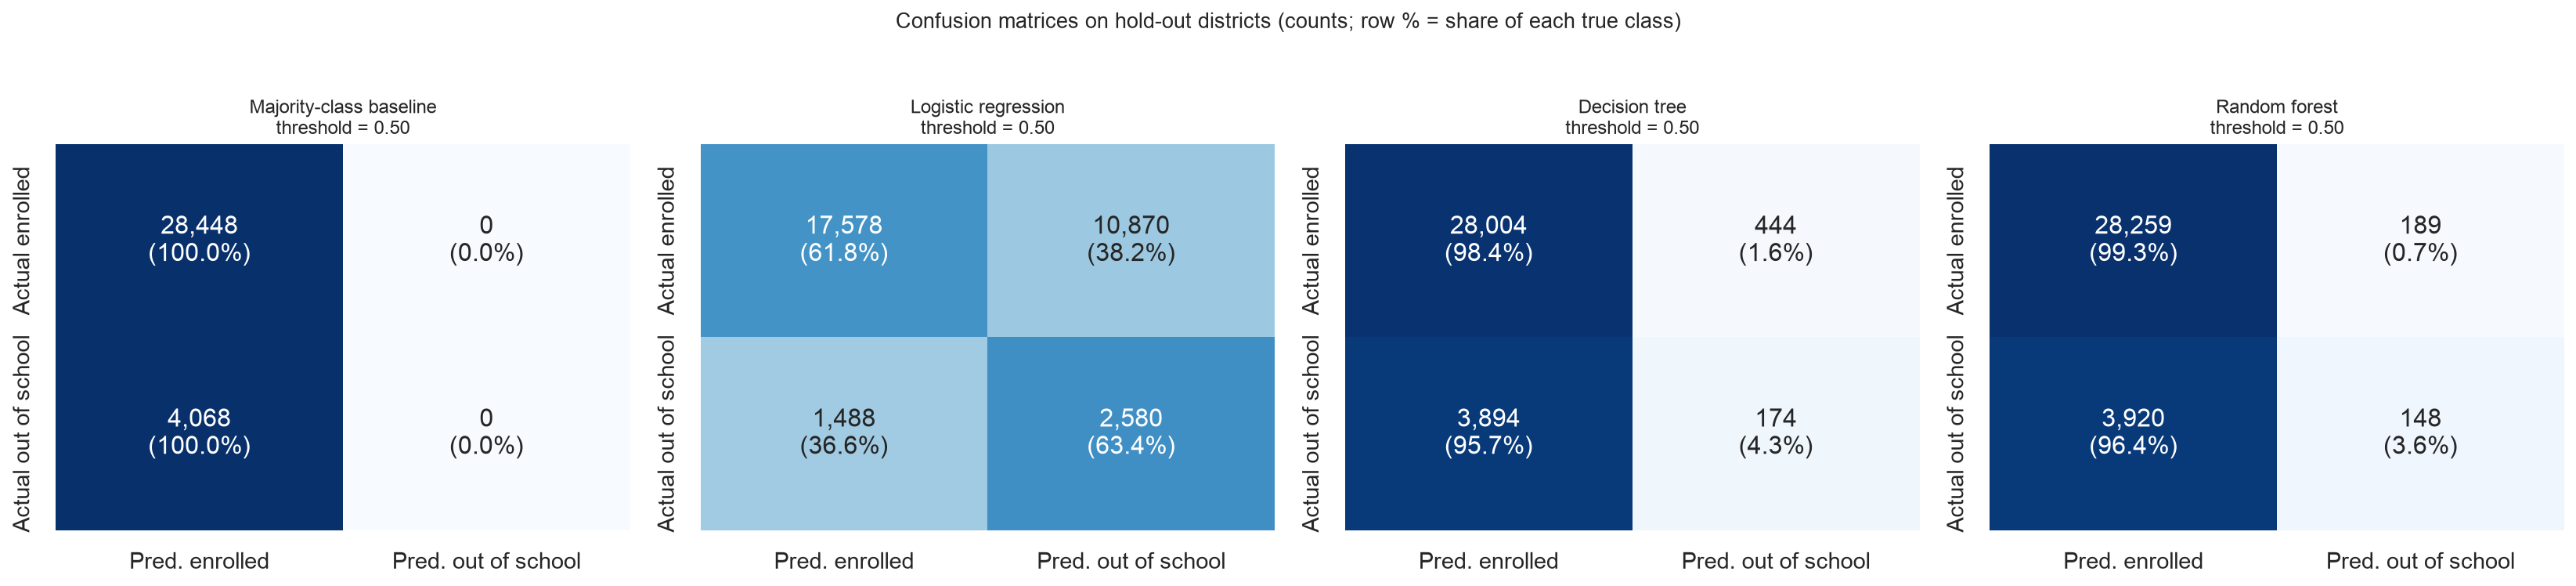

In [9]:
cms_05 = {k: {**ev.confusion(yte, (probas[k] >= 0.5).astype(int)), "threshold": 0.5} for k in ("naive", *M.MODELS)}
for k in ("naive", *M.MODELS):
    print(M.MODEL_NAMES[k], "@ 0.50"); display(ev.confusion_table(cms_05[k]))
display(Image(plots.confusion_heatmaps(cms_05, M.MODEL_NAMES, "_default")))

,model,cost_ratio_fn_to_fp,threshold,oof_recall,oof_precision,oof_cost,holdout_recall,holdout_precision,holdout_cost,holdout_oracle_thr,holdout_oracle_cost
0,logreg,1,0.93,0.0000e+00,NaN,133.1920,0.0000,NaN,125.1076,0.93,125.1076
1,logreg,3,0.60,5.3101e-01,0.2861,363.8958,0.4088,0.2001,426.3132,0.78,363.9132
2,logreg,5,0.54,6.4152e-01,0.2632,477.8748,0.5678,0.2013,552.2820,0.57,545.4545
3,logreg,10,0.43,7.9164e-01,0.2233,644.3339,0.7480,0.1809,738.9900,0.41,731.4860
4,tree,1,0.94,5.8072e-05,0.0909,133.2617,0.0000,NaN,125.1076,0.89,125.1076
5,tree,3,0.28,3.2712e-01,0.3414,352.9357,0.2891,0.2661,366.5580,0.30,365.1126
6,tree,5,0.16,6.2758e-01,0.2763,466.9843,0.6207,0.2370,487.3293,0.16,487.3293
7,tree,10,0.07,8.3449e-01,0.2127,631.8810,0.8282,0.1843,673.5453,0.09,669.8548
8,rf,1,0.87,1.7422e-04,0.6000,133.1843,0.0000,NaN,125.1076,0.73,125.1076
9,rf,3,0.18,5.7213e-01,0.2930,354.8385,0.5610,0.2514,373.7852,0.28,349.7048


thresholds chosen on training OOF (r = 5): {'logreg': 0.54, 'tree': 0.16, 'rf': 0.13}
hold-out cost per 1,000 at those thresholds (lower is better): {'tree': 487.3, 'rf': 496.2, 'logreg': 552.3}


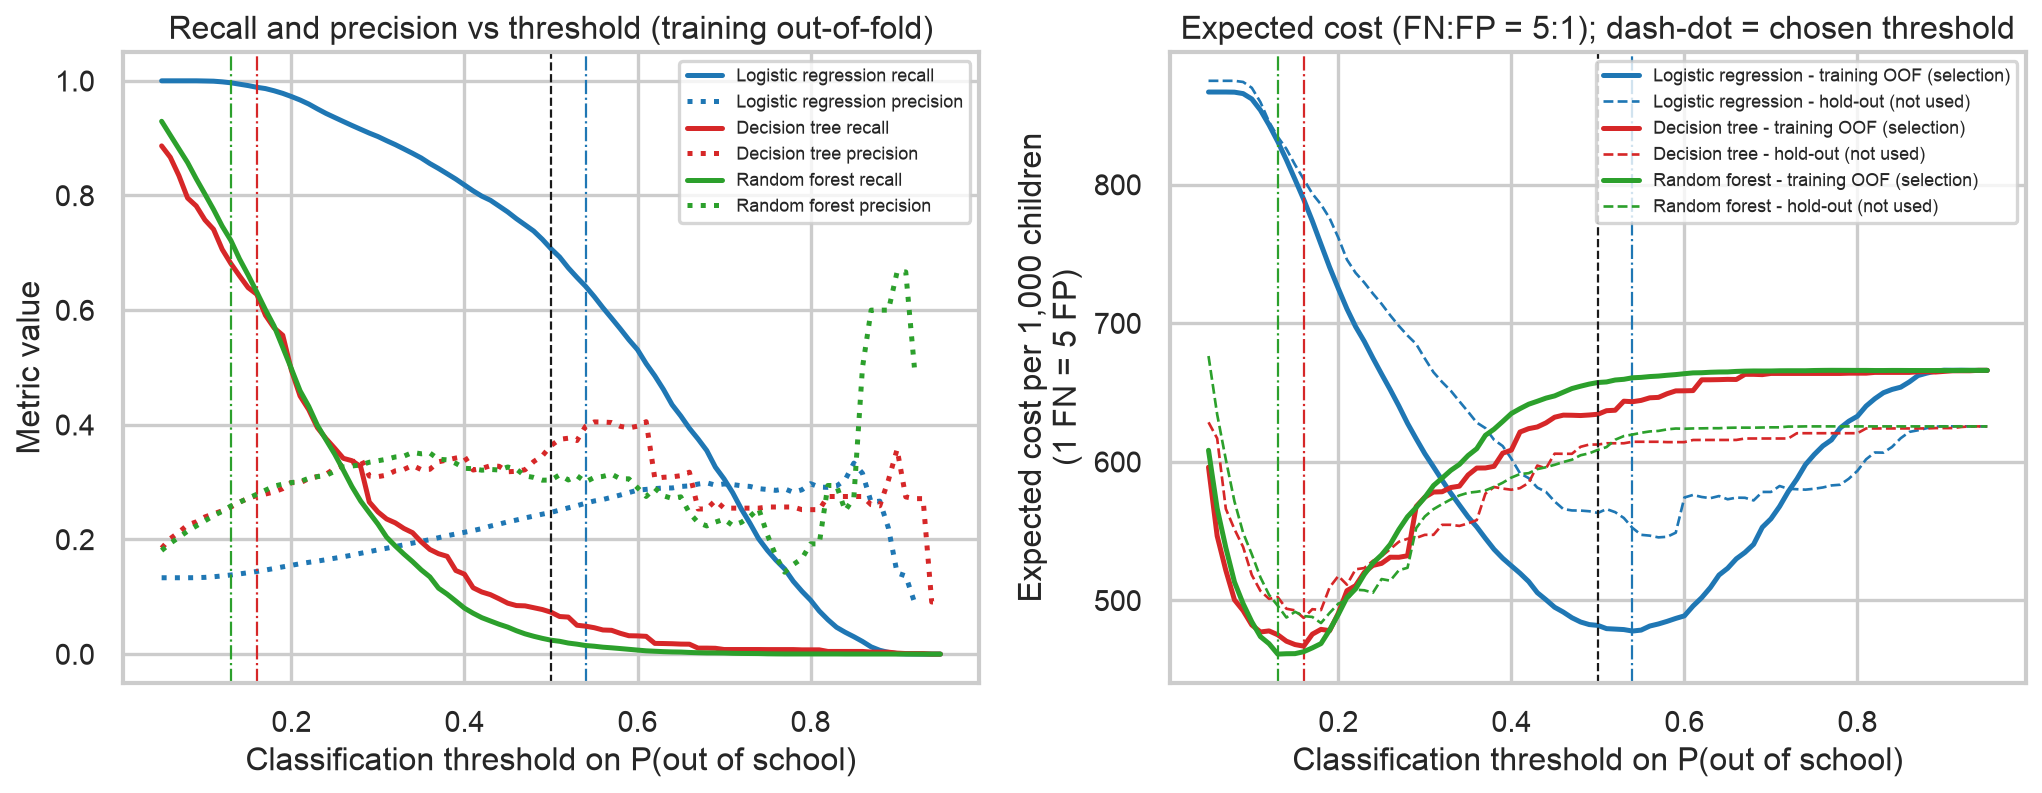

In [10]:
fitted = {"logreg": gs_lr.best_estimator_, "tree": gs_tree.best_estimator_, "rf": gs_rf.best_estimator_}
oof, sweeps_oof, sweeps_ho, best = {}, {}, {}, []
for k in M.MODELS:
    oof[k] = cross_val_predict(clone(fitted[k]), Xtr, ytr, groups=gtr, cv=make_inner_cv(), method="predict_proba", n_jobs=-1)[:, 1]
    sweeps_oof[k] = ev.threshold_sweep(ytr, oof[k])          # selection: training out-of-fold
    sweeps_ho[k] = ev.threshold_sweep(yte, probas[k])        # reported only
    b = ev.best_thresholds(sweeps_oof[k]); b.insert(0, "model", k)
    for i, r in b.iterrows():
        c = ev.confusion(yte, (probas[k] >= r["threshold"]).astype(int)); m = ev.metrics_from_counts(c)
        b.loc[i, "holdout_recall"], b.loc[i, "holdout_precision"] = m["recall"], m["precision"]
        b.loc[i, "holdout_cost"] = ev.expected_cost(c, r["cost_ratio_fn_to_fp"])
        col = f"cost_per_1000_ratio{int(r['cost_ratio_fn_to_fp'])}"
        b.loc[i, "holdout_oracle_thr"] = sweeps_ho[k].loc[sweeps_ho[k][col].idxmin(), "threshold"]
        b.loc[i, "holdout_oracle_cost"] = sweeps_ho[k][col].min()
    best.append(b)
best = pd.concat(best, ignore_index=True).rename(columns={"recall": "oof_recall", "precision": "oof_precision", "cost_per_1000": "oof_cost"})
display(best[["model", "cost_ratio_fn_to_fp", "threshold", "oof_recall", "oof_precision", "oof_cost", "holdout_recall", "holdout_precision", "holdout_cost", "holdout_oracle_thr", "holdout_oracle_cost"]])
rec_thr = {k: float(best[(best.model == k) & (best.cost_ratio_fn_to_fp == C.RECOMMENDED_COST_RATIO)].threshold.item()) for k in M.MODELS}
print("thresholds chosen on training OOF (r = 5):", rec_thr)
r5 = best[best.cost_ratio_fn_to_fp == C.RECOMMENDED_COST_RATIO].set_index("model")["holdout_cost"].sort_values()
print("hold-out cost per 1,000 at those thresholds (lower is better):", r5.round(1).to_dict())
display(Image(plots.threshold_curves(sweeps_oof, sweeps_ho, rec_thr, M.MODEL_NAMES, C.RECOMMENDED_COST_RATIO)))

,model,threshold,t,recall,precision,specificity,f1,flagged_per_1000,caught_per_1000,missed_per_1000,false_alarms_per_1000,cost/1000 (r=5)
0,naive,0.50 default,0.50,0.0000,NaN,1.0000,0.0000,0.0000,0.0000,125.1076,0.0000,625.5382
1,logreg,0.50 default,0.50,0.6342,0.1918,0.6179,0.2946,413.6425,79.3456,45.7621,334.2970,563.1074
2,logreg,recommended,0.54,0.5678,0.2013,0.6777,0.2972,352.9954,71.0419,54.0657,281.9535,552.2820
3,tree,0.50 default,0.50,0.0428,0.2816,0.9844,0.0743,19.0060,5.3512,119.7564,13.6548,612.4370
4,tree,recommended,0.16,0.6207,0.2370,0.7142,0.3430,327.7156,77.6541,47.4536,250.0615,487.3293
5,rf,0.50 default,0.50,0.0364,0.4392,0.9934,0.0672,10.3641,4.5516,120.5560,5.8125,608.5927
6,rf,recommended,0.13,0.7087,0.2202,0.6412,0.3360,402.6018,88.6640,36.4436,313.9378,496.1557


Logistic regression @ 0.54


,Predicted: enrolled (0),Predicted: out of school (1)
Actual: enrolled (0),"19,280 (67.8%)","9,168 (32.2%)"
Actual: out of school (1),"1,758 (43.2%)","2,310 (56.8%)"


Decision tree @ 0.16


,Predicted: enrolled (0),Predicted: out of school (1)
Actual: enrolled (0),"20,317 (71.4%)","8,131 (28.6%)"
Actual: out of school (1),"1,543 (37.9%)","2,525 (62.1%)"


Random forest @ 0.13


,Predicted: enrolled (0),Predicted: out of school (1)
Actual: enrolled (0),"18,240 (64.1%)","10,208 (35.9%)"
Actual: out of school (1),"1,185 (29.1%)","2,883 (70.9%)"


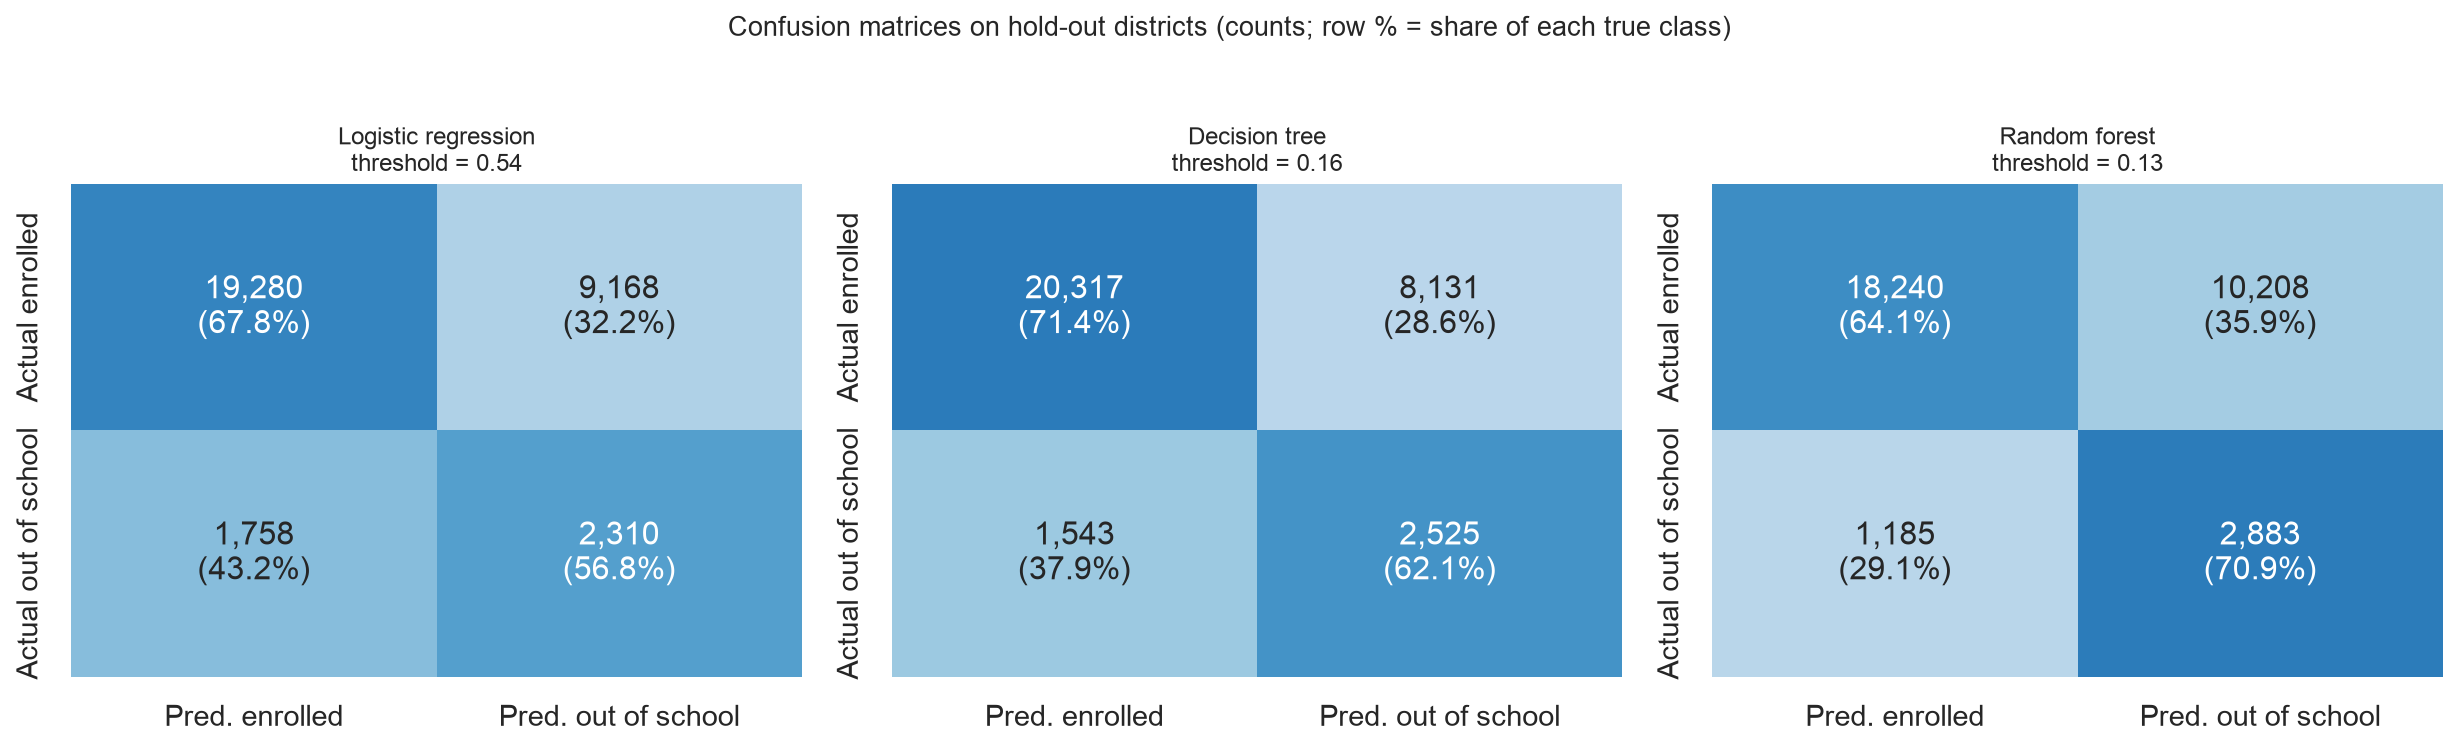

In [11]:
cms_rec = {k: {**ev.confusion(yte, (probas[k] >= t).astype(int)), "threshold": t} for k, t in rec_thr.items()}
rows = []
for k in ("naive", *M.MODELS):
    for lab, cm in (("0.50 default", cms_05[k]), ("recommended", cms_rec.get(k))):
        if cm is None: continue
        rows.append({"model": k, "threshold": lab, "t": cm["threshold"], **ev.metrics_from_counts(cm), **ev.per_1000(cm),
                     "cost/1000 (r=5)": ev.expected_cost(cm, 5)})
display(pd.DataFrame(rows)[["model", "threshold", "t", "recall", "precision", "specificity", "f1", "flagged_per_1000", "caught_per_1000", "missed_per_1000", "false_alarms_per_1000", "cost/1000 (r=5)"]])
for k in M.MODELS:
    print(M.MODEL_NAMES[k], f"@ {rec_thr[k]:.2f}"); display(ev.confusion_table(cms_rec[k]))
display(Image(plots.confusion_heatmaps(cms_rec, M.MODEL_NAMES, "_recommended")))

**Interpretation.**
- With r = 1 (errors equally costly) the cheapest policy is to flag nobody: the models are not sharp enough to beat
  the base rate when a false alarm costs as much as a missed child. This is the honest baseline the cost framing
  exposes.
- Once a missed child is weighted 3-5x a wasted visit, the optimum moves to a low threshold that flags roughly a
  third to 40% of all children and catches 55-70% of those out of school on unseen districts. At r = 10 the models flag
  over half of all children to catch 75-85%.
- **Ranking by hold-out cost at training-chosen thresholds (r = 5):** decision tree ~487 per 1,000, random forest ~496,
  logistic regression ~552.
- **Recommendation for deployment (r = 5).** Decision tree at threshold 0.16 (chosen on training OOF): per 1,000
  children screened on the hold-out it flags ~328, catches ~78 of the ~125 out-of-school children and misses ~47, at the
  lowest hold-out expected cost. The default 0.5 cut-off on the same tree would catch only ~5 per 1,000 - unusable for
  outreach. The random forest at 0.13 catches more (recall ~0.71, ~89 per 1,000) but flags ~403 per 1,000 to do it;
  it has the best ranking quality (highest AUC) yet its training-chosen threshold sits a little below its hold-out
  optimum (0.18), so on the honest comparison the single tree edges it by ~2% of cost - a gap within the fold-to-fold
  noise, so stability and explainability should decide between them. Logistic regression at 0.54 (recall ~0.57,
  precision ~0.20) is preferable where officials need to explain *why* a child was flagged.
- **Honesty check.** Had the thresholds been picked on the hold-out itself: logistic optimum 0.57 (cost ~545 vs ~552 at
  the training-selected 0.54); tree 0.16 either way; forest 0.18 (cost ~484 vs ~496 at 0.13). The flattery from
  selecting on the test set would have been at most ~2.6% of cost - small but not zero, which is why every number at the
  recommended threshold below uses the training-selected value.
- Which error is "better" to make depends on budget: a programme that can afford to visit a third of households
  should accept the false positives; one that cannot should raise the threshold and accept more missed children,
  explicitly.

## 7. Misclassified edge cases

Who does the logistic model miss (false negatives) compared with the children it catches (true positives)?

In [12]:
thr = rec_thr["logreg"]; yhat = (probas["logreg"] >= thr).astype(int)
outcome = np.select([(yte == 1) & (yhat == 1), (yte == 1) & (yhat == 0), (yte == 0) & (yhat == 1)], ["TP", "FN", "FP"], "TN")
prof = df_te[C.FEATURES].copy(); prof["province"] = province_of(df_te); prof["outcome"] = outcome; prof["p_hat"] = probas["logreg"]
num = [f for f in C.FEATURES if not f.startswith("province_")] + ["p_hat"]
profile = prof.groupby("outcome")[num].mean().T; profile["FN - TP"] = profile["FN"] - profile["TP"]
display(profile)
display(pd.crosstab(prof["province"], prof["outcome"], normalize="index").assign(n=prof["province"].value_counts()))

outcome,FN,FP,TN,TP,FN - TP
age,9.7474,8.7484,9.7493,8.7095,1.0379
female,0.3794,0.3837,0.3398,0.4485,-0.0691
urban,0.4437,0.1645,0.3901,0.1541,0.2896
female_x_urban,0.1854,0.0666,0.1403,0.0779,0.1075
bform,0.5495,0.4191,0.6596,0.3130,0.2365
any_disability,0.0648,0.1439,0.0989,0.1264,-0.0616
assets_n,3.0461,2.1488,3.7207,1.7883,1.2578
digital_n,2.3305,1.2586,3.2066,1.1225,1.2080
house,2.1945,1.2717,2.4094,1.2602,0.9344
p_hat,0.3832,0.6684,0.3195,0.6843,-0.3011


outcome,FN,FP,TN,TP,n
province,,,,,
Balochistan,0.0133,0.6341,0.1933,0.1592,6223
Khyber Pakhtuknkhwa,0.0584,0.2356,0.6267,0.0792,7889
Punjab,0.0484,0.2310,0.6861,0.0345,13387
Sindh,0.1128,0.0540,0.7869,0.0462,5017


,variable,level,n,positives,prevalence,recall,fnr,precision,roc_auc,flag_small
0,female,0,20744,2365,0.1140,0.5387,0.4613,0.1840,0.6683,False
1,female,1,11772,1703,0.1447,0.6083,0.3917,0.2275,0.6778,False
2,urban,0,22350,2932,0.1312,0.6664,0.3336,0.2032,0.6814,False
3,urban,1,10166,1136,0.1117,0.3134,0.6866,0.1910,0.6609,False
4,any_disability,0,28884,3662,0.1268,0.5511,0.4489,0.2045,0.6737,False
5,any_disability,1,3632,406,0.1118,0.7192,0.2808,0.1813,0.7064,False
6,bform,1,18249,1689,0.0926,0.4281,0.5719,0.1584,0.6745,False
7,bform,0,14267,2379,0.1667,0.6671,0.3329,0.2296,0.6356,False
8,province,Sindh,5017,798,0.1591,0.2907,0.7093,0.4612,0.8453,False
9,province,Khyber Pakhtuknkhwa,7889,1086,0.1377,0.5755,0.4245,0.2516,0.7051,False


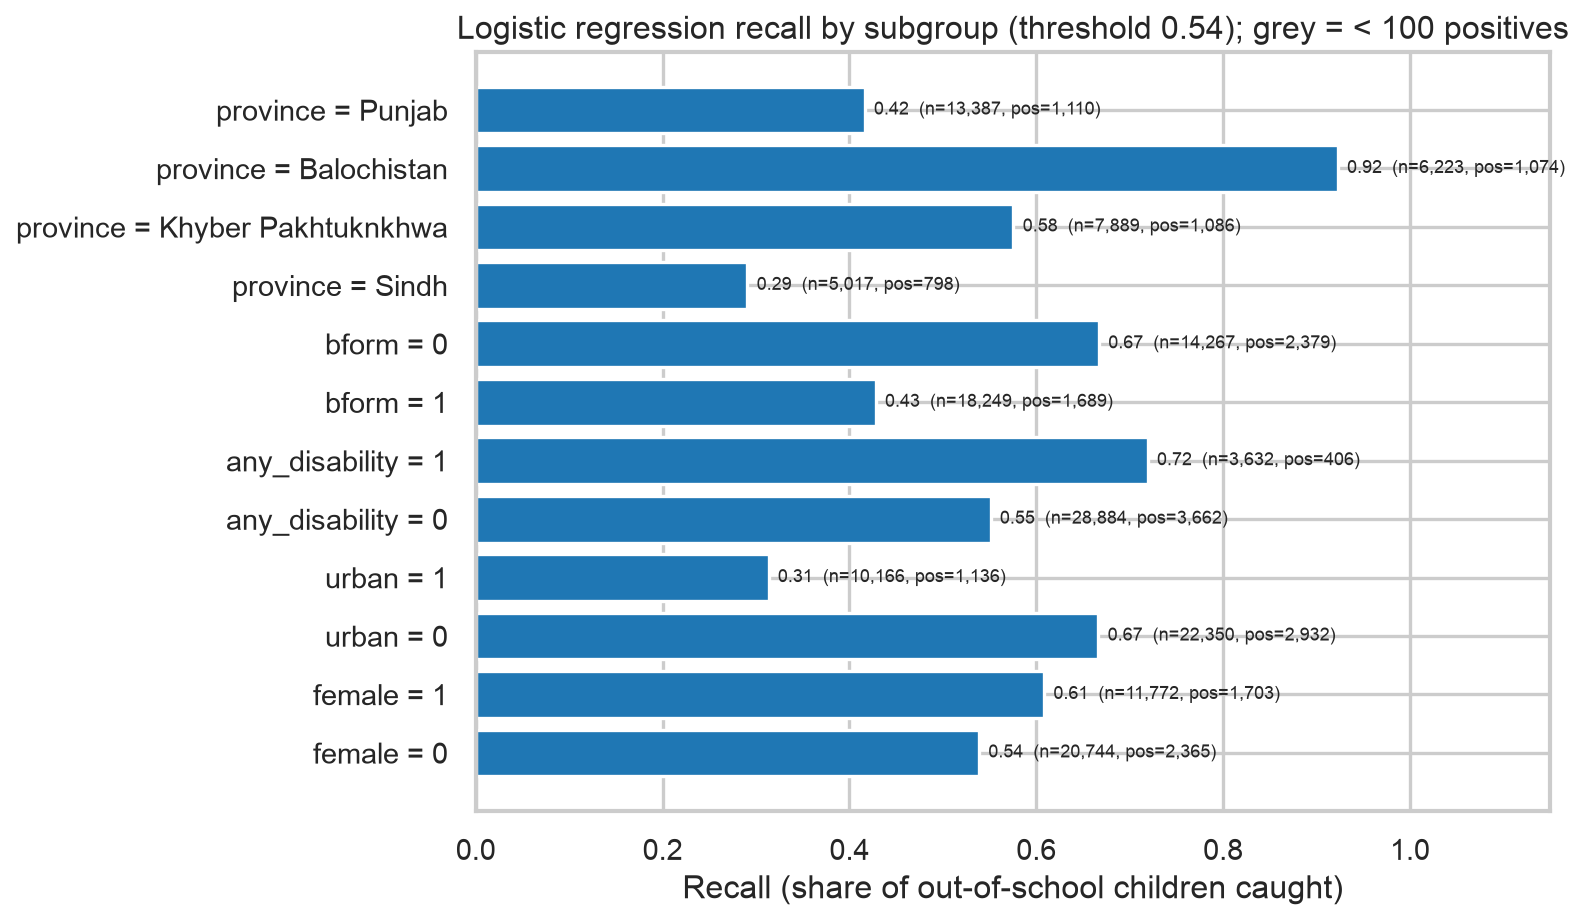

Milestone 2 subgroup sample sizes (population):


,variable,level,n,positives,negatives,prevalence,flag_small
0,female,0,99668,12159,87509,0.1220,False
1,female,1,62135,9129,53006,0.1469,False
2,urban,0,101302,15182,86120,0.1499,False
3,urban,1,60501,6106,54395,0.1009,False
4,any_disability,0,141133,17508,123625,0.1241,False
5,any_disability,1,20670,3780,16890,0.1829,False
6,bform,0,67617,11784,55833,0.1743,False
7,bform,1,94186,9504,84682,0.1009,False
8,province,Balochistan,32302,8415,23887,0.2605,False
9,province,Islamabad Capital Territory,807,52,755,0.0644,True


In [13]:
groupings = {"female": df_te["female"], "urban": df_te["urban"], "any_disability": df_te["any_disability"], "bform": df_te["bform"], "province": province_of(df_te)}
sub = ev.subgroup_metrics(df_te, yte, probas["logreg"], thr, groupings)
display(sub[["variable", "level", "n", "positives", "prevalence", "recall", "fnr", "precision", "roc_auc", "flag_small"]])
display(Image(plots.subgroup_recall_plot(sub, f"Logistic regression recall by subgroup (threshold {thr:.2f}); grey = < 100 positives")))
print("Milestone 2 subgroup sample sizes (population):"); display(load_subgroup_counts())

**Systematic weaknesses.** The children the model misses look like *enrolled* children on paper: they are older,
more often urban (44% vs 15% of true positives), more often B-form registered, and come from households with more
assets, more digital use and better housing. In other words the model has learned "poor rural household => out of
school" and under-detects **out-of-school children in better-off or urban households** - plausibly dropouts rather
than never-enrolled children, a distinction the current features cannot see. Recall is far higher in Balochistan
(~0.92, where prevalence is 26%) than in Sindh (~0.29) or Punjab (~0.42): the model leans on the province prior. Urban
children have recall ~0.31 versus ~0.67 for rural children. Islamabad Capital Territory contains a single district and
fell entirely into the training side of the grouped split, so it has no hold-out estimate at all - and with 52
positives in the whole dataset it is too small for any reliable subgroup conclusion.

## 8. Feature importance and the five hypotheses

Three complementary views: odds ratios with 95% confidence intervals from an unpenalised logistic fit on the training
districts (inference), standardised coefficients from the tuned sklearn pipeline, Gini importance from the tuned tree
and forest, and permutation importance (drop in hold-out ROC-AUC when a feature is shuffled) for all three learners.

,label,odds_ratio,or_ci_low,or_ci_high,p_value,std_coef
0,Housing (1 kachha - 3 pacca),0.5645,0.5494,0.5800,0.0000e+00,-0.4660
1,Digital use (0-5),0.8172,0.8059,0.8287,1.1867e-176,-0.3230
2,Province: Balochistan,1.7905,1.7119,1.8727,1.1909e-142,0.2337
3,Any disability,1.8767,1.7952,1.9619,5.4479e-170,0.2129
4,Female,1.4759,1.4164,1.5379,8.0797e-77,0.1898
5,B-form registered,0.7530,0.7270,0.7800,2.7096e-56,-0.1397
6,Female x Urban,0.7691,0.7136,0.8289,6.4137e-12,-0.0949
7,Household assets (0-8),0.9638,0.9515,0.9763,1.9615e-08,-0.0575
8,Urban,0.8901,0.8478,0.9345,2.7360e-06,-0.0568
9,Province: Sindh,0.8890,0.8426,0.9379,1.6833e-05,-0.0541


McFadden pseudo-R2 = 0.118


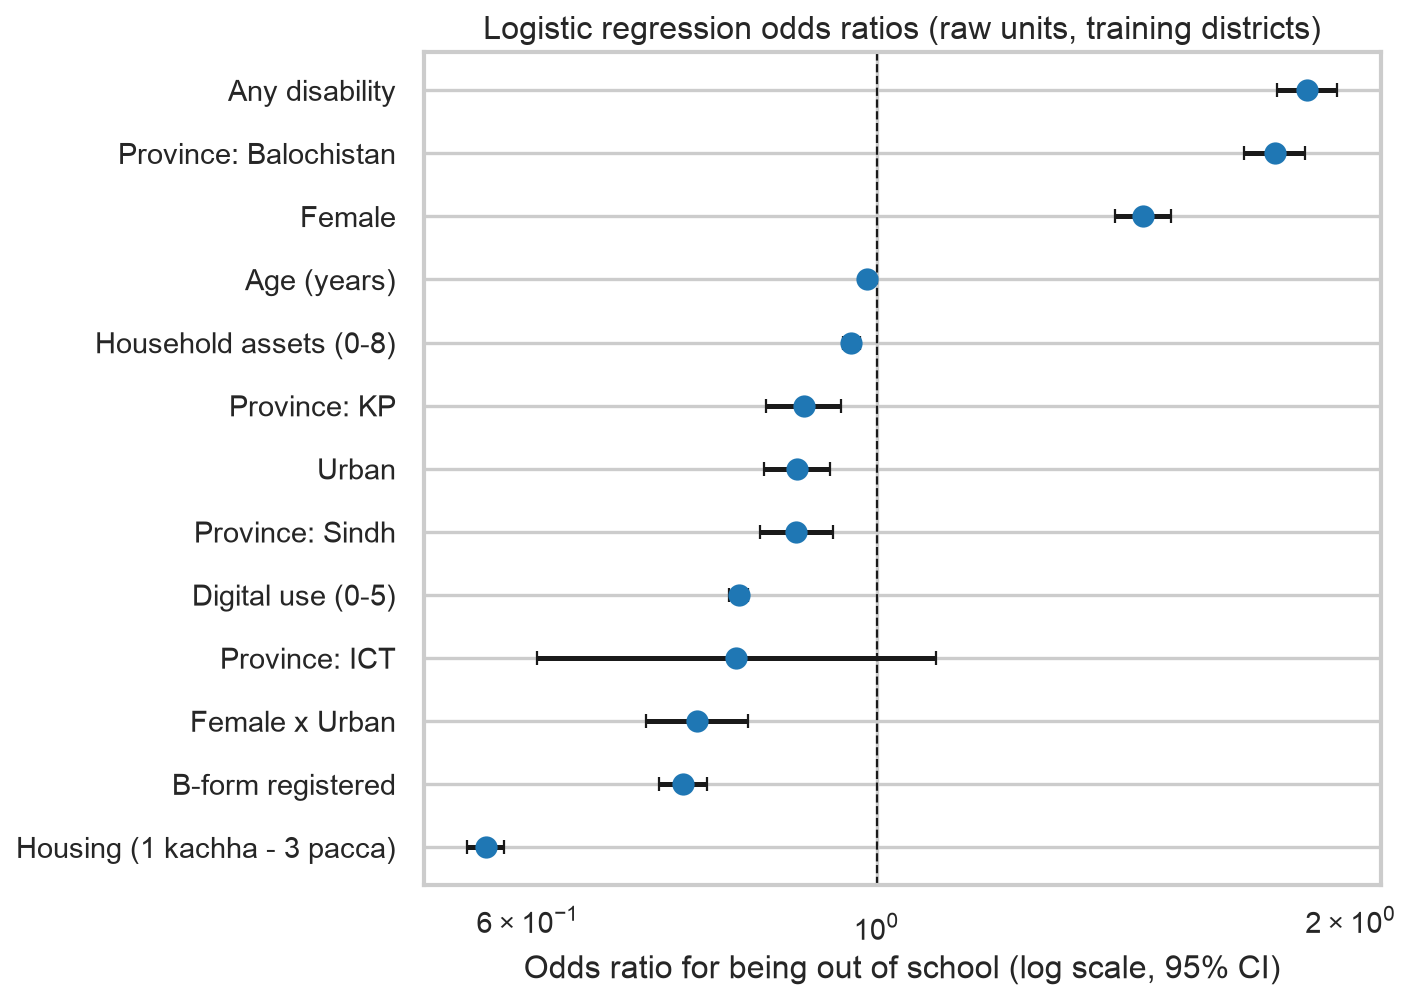

In [14]:
ors = imp.logit_odds_ratios(Xtr, ytr)
display(ors[["label", "odds_ratio", "or_ci_low", "or_ci_high", "p_value", "std_coef"]])
print(f"McFadden pseudo-R2 = {ors['pseudo_r2'].iloc[0]:.3f}")
display(Image(plots.odds_ratio_forest(ors)))

,feature,LR |std coef| rank,Tree Gini rank,LR permutation rank,Tree permutation rank,Forest Gini rank,Forest permutation rank
8,house,1,1,2,2,1,2
7,digital_n,2,3,1,1,2,1
6,assets_n,7,4,5,4,3,4
11,province_Balochistan,3,2,6,7,4,7
0,age,9,5,7,3,5,3
5,any_disability,4,6,9,10,6,9
4,bform,6,8,3,6,7,6
1,female,5,7,4,5,8,5
2,urban,8,11,11,13,9,13
9,province_Sindh,11,9,13,9,10,10


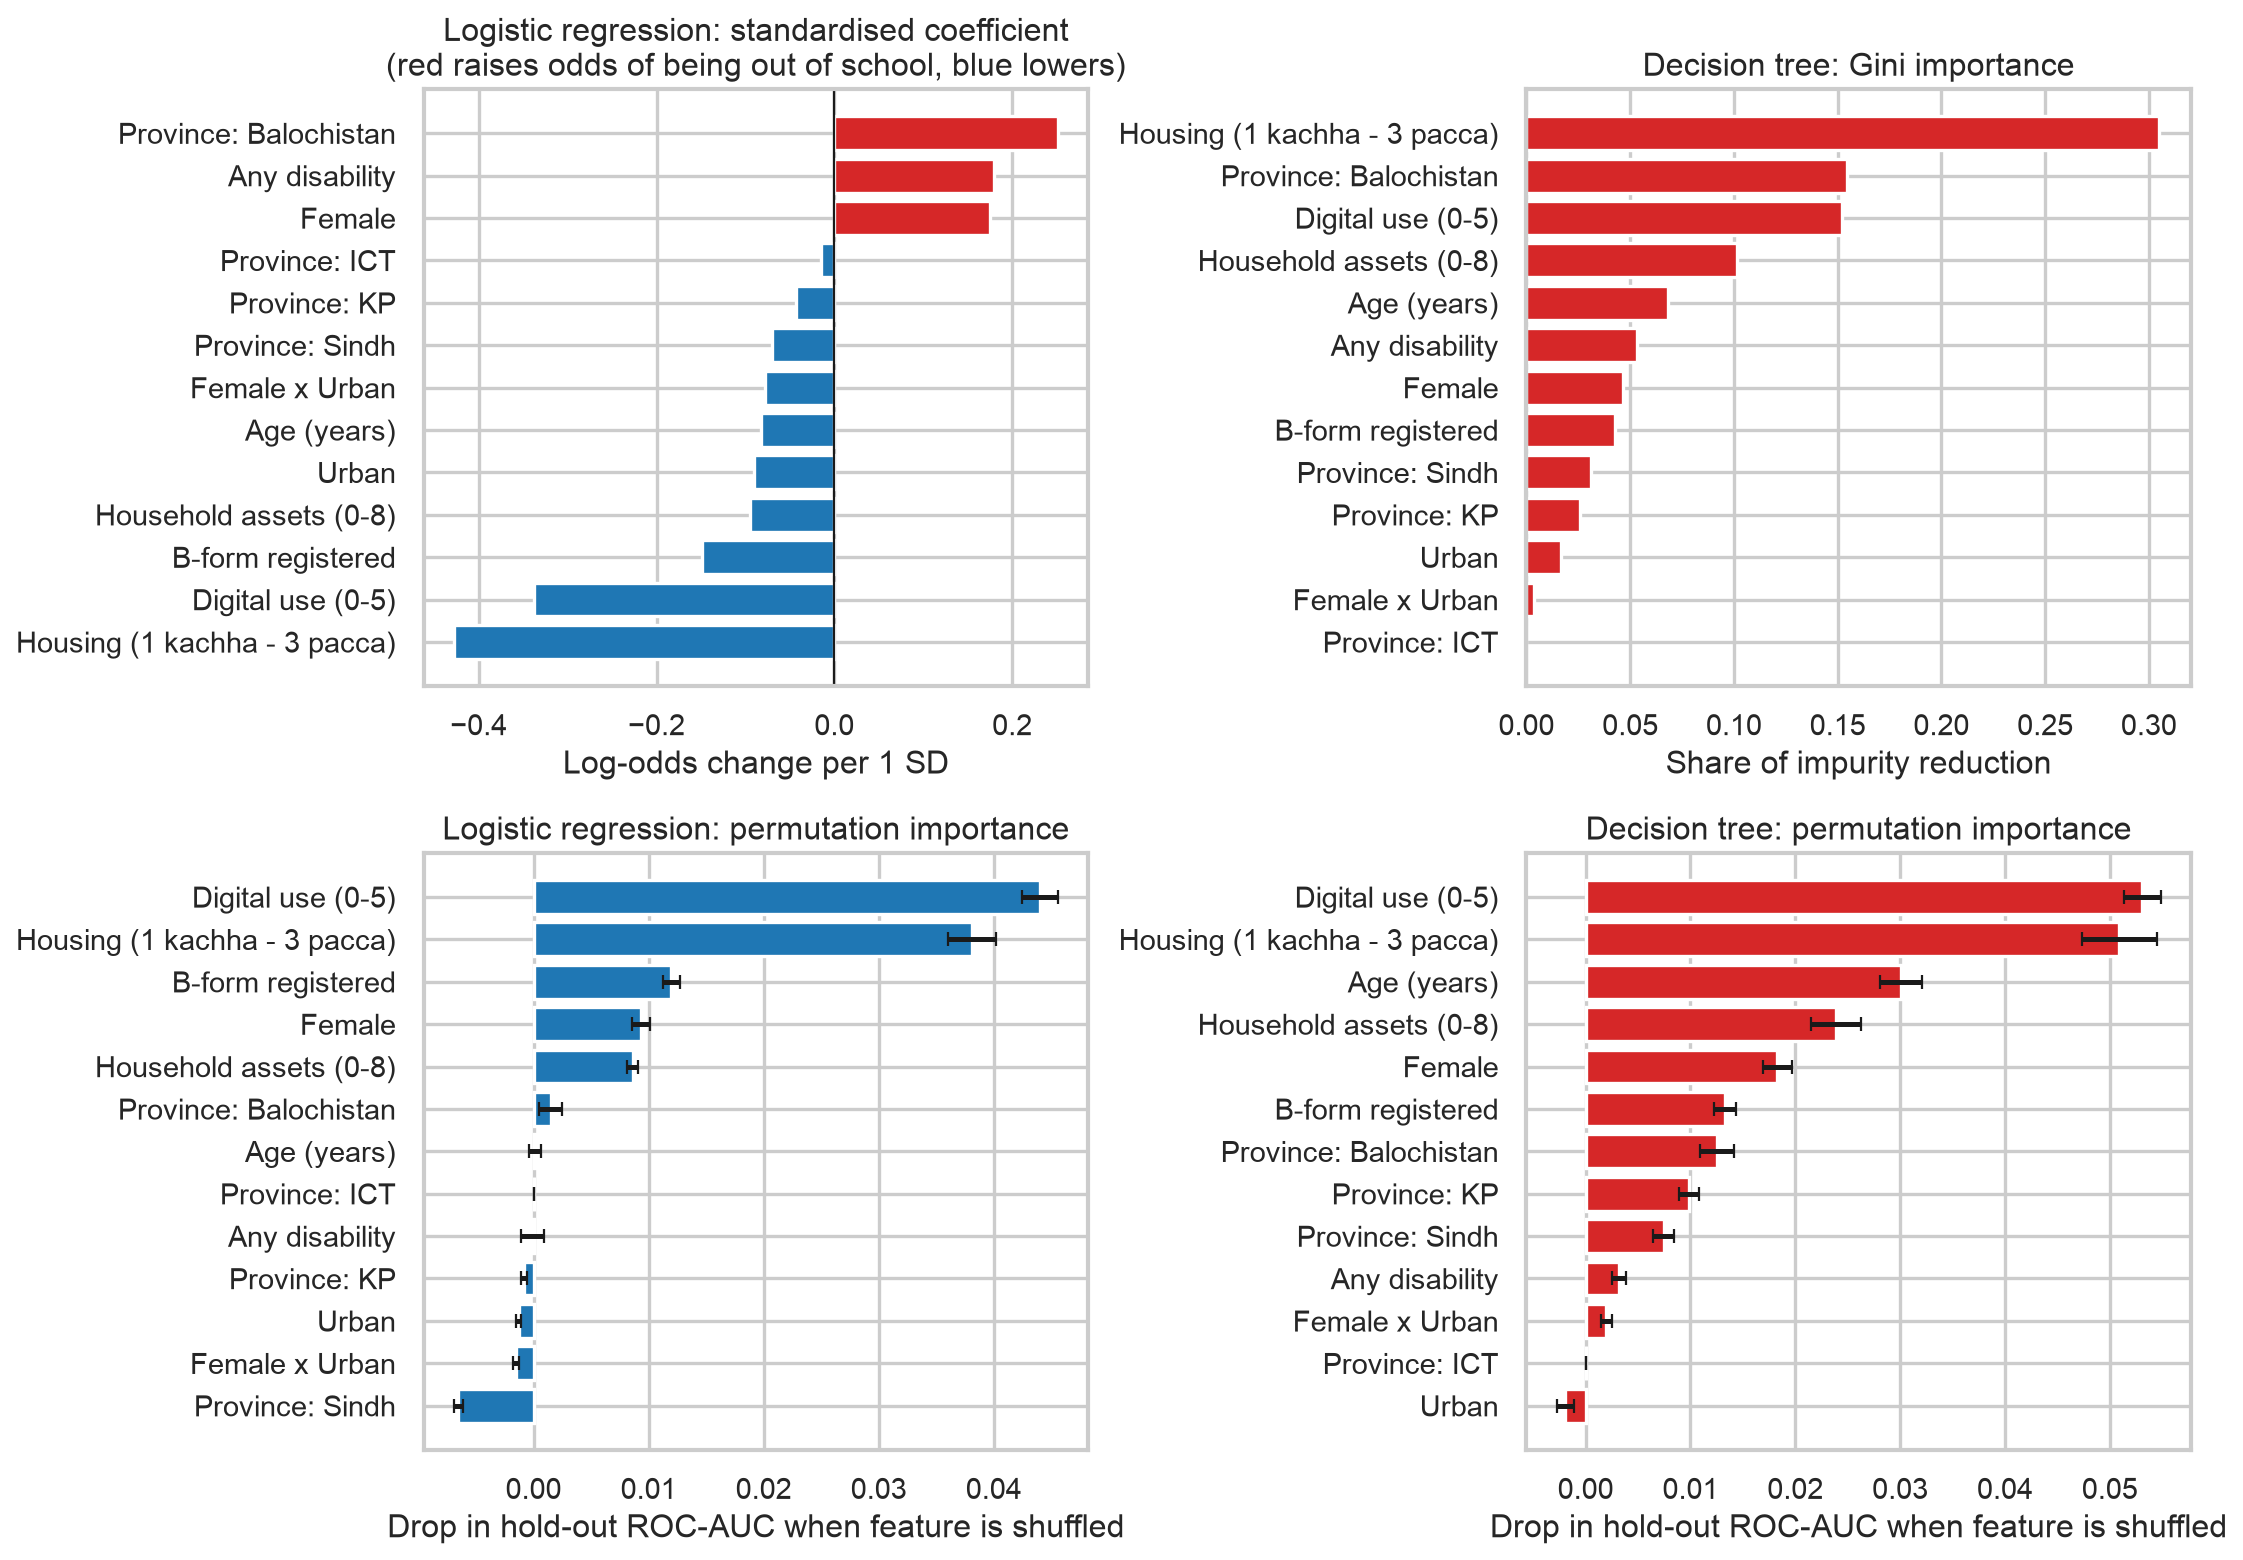

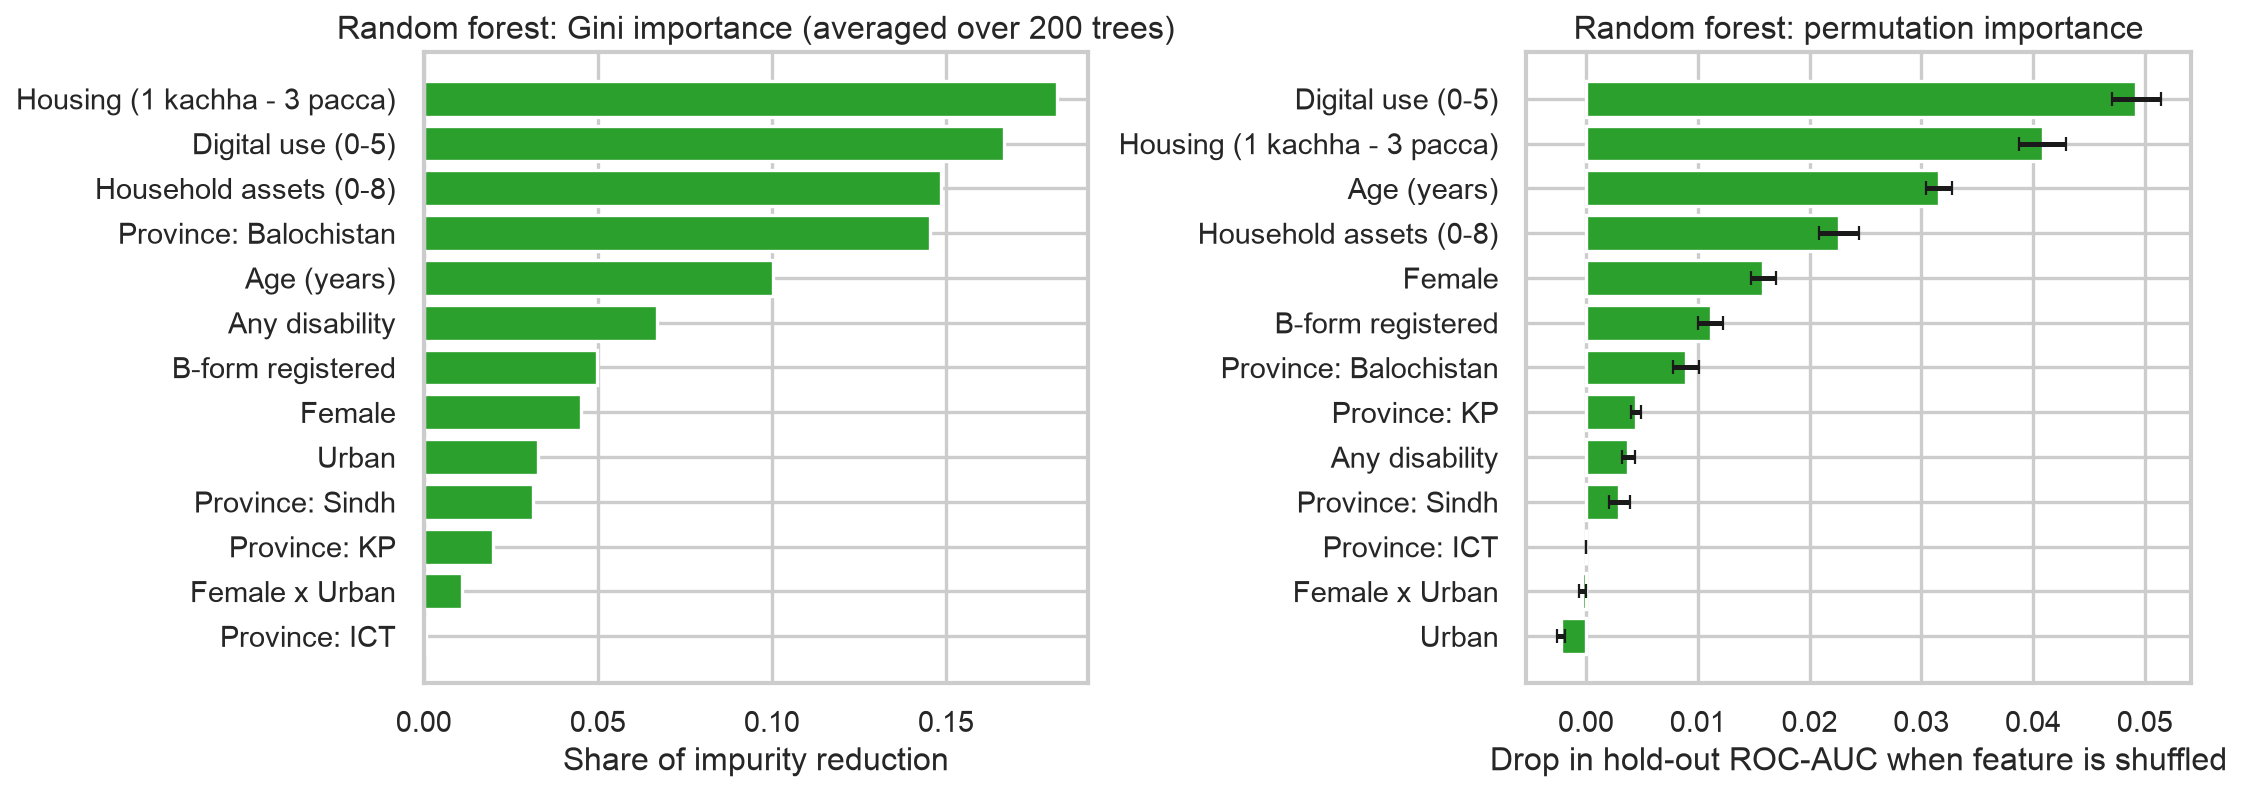

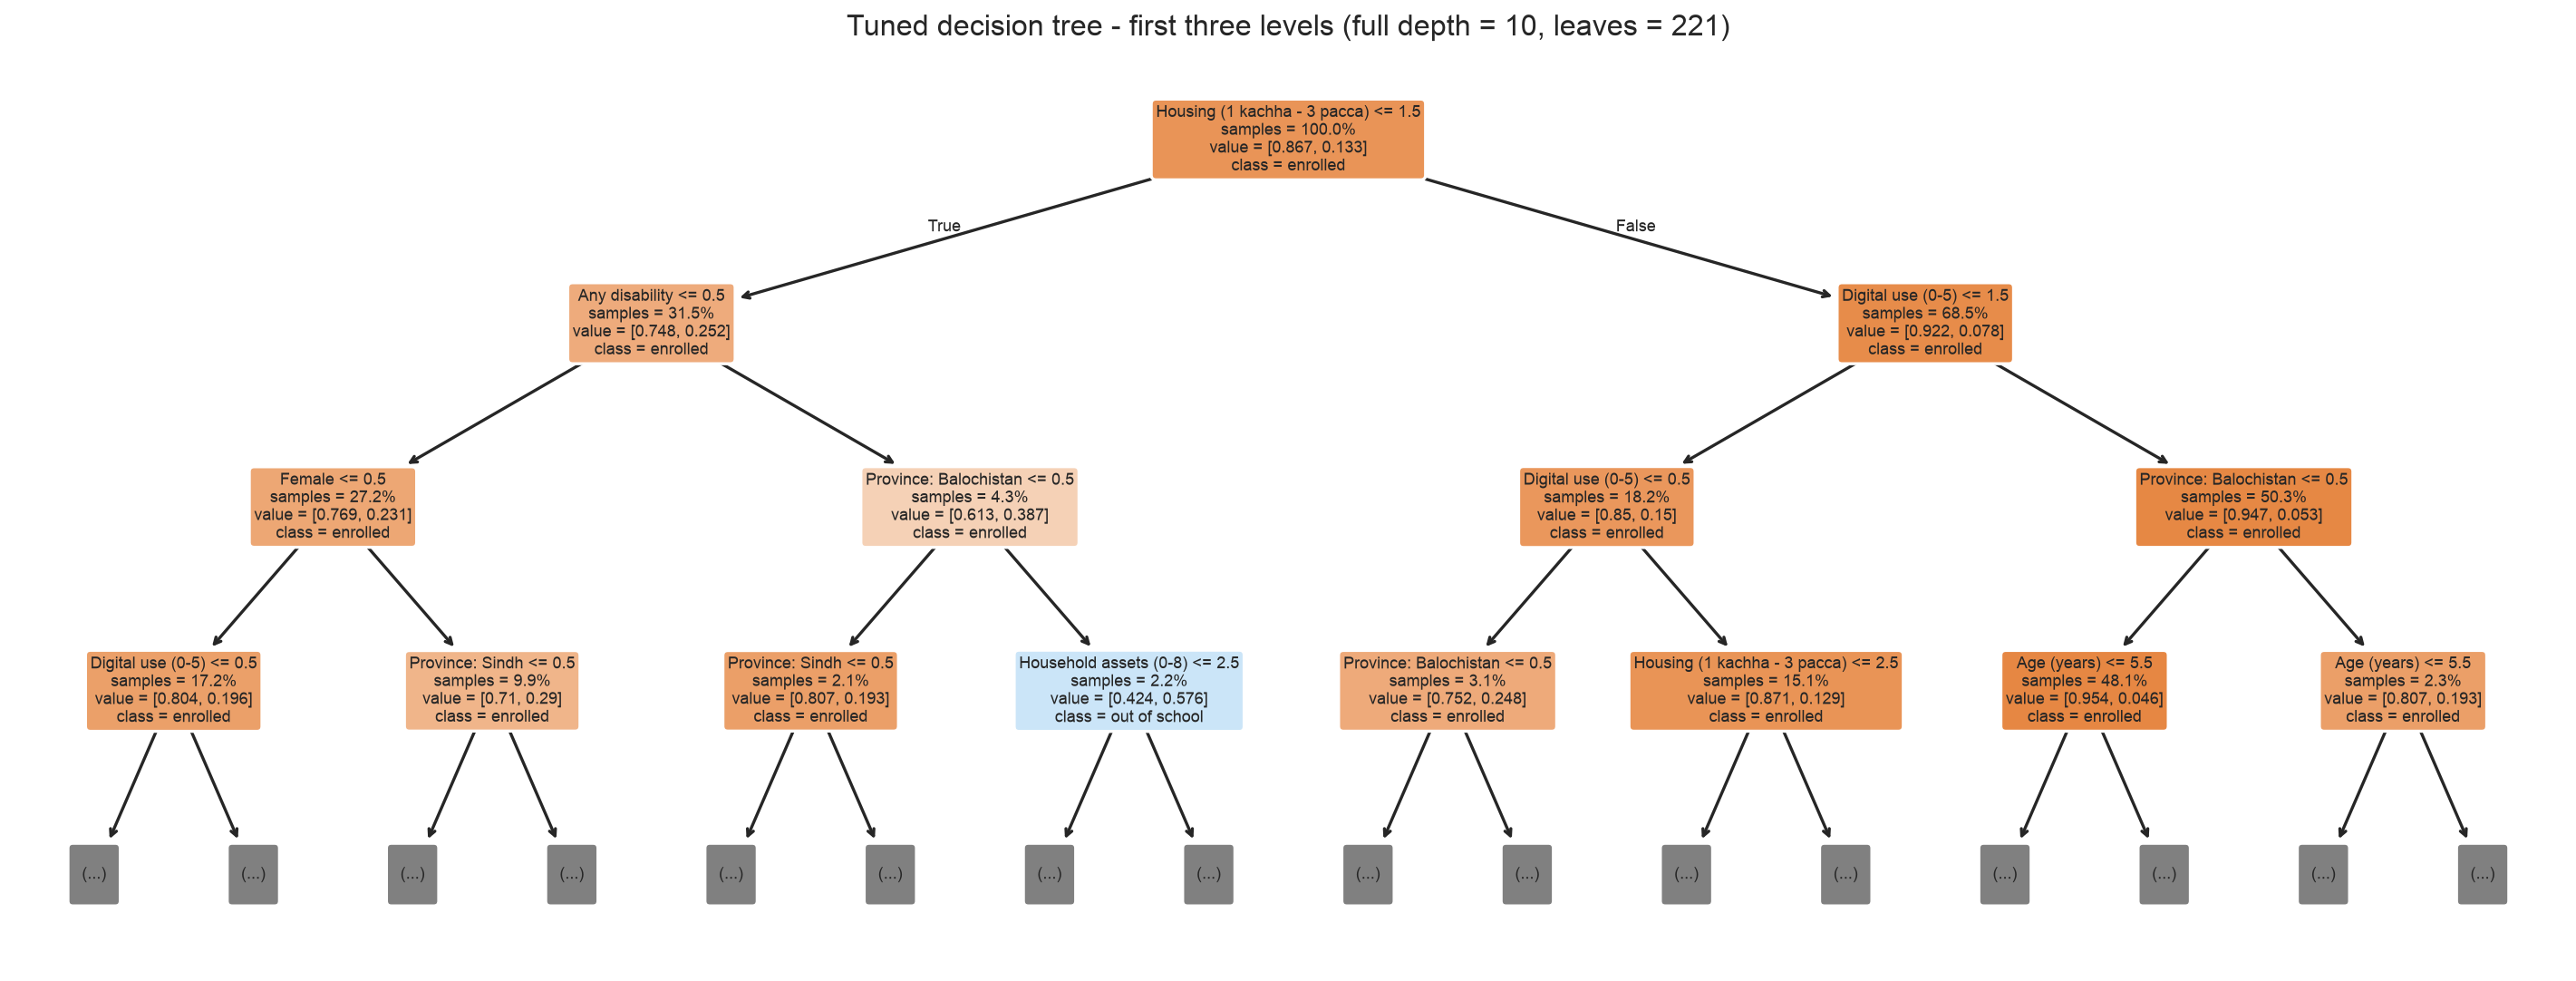

In [15]:
sk_coef = imp.sklearn_logreg_coefs(gs_lr.best_estimator_)
gini = imp.tree_gini(gs_tree.best_estimator_)
perm_lr = imp.permutation(gs_lr.best_estimator_, Xte, yte)
perm_tree = imp.permutation(gs_tree.best_estimator_, Xte, yte)
gini_rf = imp.tree_gini(gs_rf.best_estimator_)
perm_rf = imp.permutation(gs_rf.best_estimator_, Xte, yte)
rank = pd.DataFrame({"feature": C.FEATURES})
rank["LR |std coef| rank"] = rank.feature.map({f: i + 1 for i, f in enumerate(sk_coef.feature)})
rank["Tree Gini rank"] = rank.feature.map({f: i + 1 for i, f in enumerate(gini.feature)})
rank["LR permutation rank"] = rank.feature.map({f: i + 1 for i, f in enumerate(perm_lr.feature)})
rank["Tree permutation rank"] = rank.feature.map({f: i + 1 for i, f in enumerate(perm_tree.feature)})
rank["Forest Gini rank"] = rank.feature.map({f: i + 1 for i, f in enumerate(gini_rf.feature)})
rank["Forest permutation rank"] = rank.feature.map({f: i + 1 for i, f in enumerate(perm_rf.feature)})
display(rank.sort_values("Forest Gini rank"))
display(Image(plots.importance_bars(sk_coef, gini, perm_lr, perm_tree)))
display(Image(plots.rf_importance_bars(gini_rf, perm_rf)))
display(Image(plots.tree_top_levels(gs_tree.best_estimator_, C.FEATURES)))

,female,urban,cell,p_out_of_school
0,0,0,"Boy, rural",0.3881
1,0,1,"Boy, urban",0.3453
2,1,0,"Girl, rural",0.4762
3,1,1,"Girl, urban",0.3788


gender gap (girl - boy) rural = +0.088; urban = +0.033


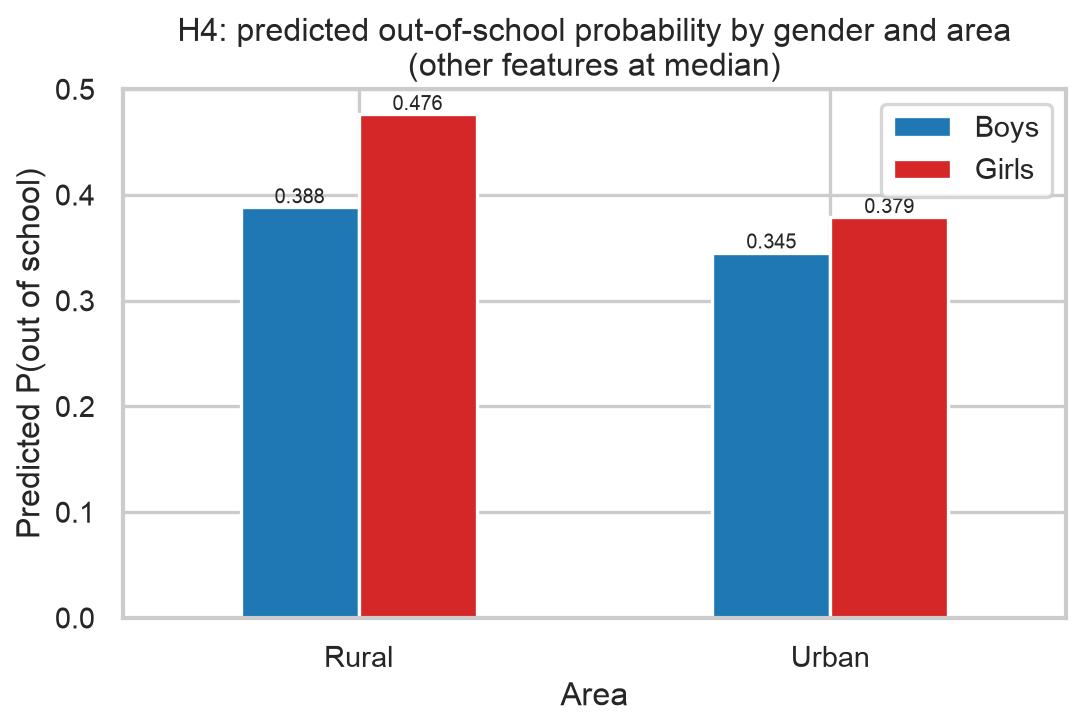

In [16]:
cells = imp.gender_area_cells(gs_lr.best_estimator_, Xtr)
display(cells)
print(f"gender gap (girl - boy) rural = {cells.attrs['rural_gender_gap']:+.3f}; urban = {cells.attrs['urban_gender_gap']:+.3f}")
display(Image(plots.gender_area_plot(cells)))

### Reading the drivers against the Milestone 2 hypotheses

| Hypothesis | Variable | Evidence | Verdict |
|---|---|---|---|
| **H1 Poverty** - higher asset count lowers the odds | `assets_n` | OR ~ 0.96 per additional asset (95% CI excludes 1); 4th in Gini importance. Direction as hypothesised, but the effect per asset is small - **housing quality** (`house`, OR ~ 0.56 per step kachha -> pacca) and **digital access** (`digital_n`, OR ~ 0.82 per service) are the dominant poverty signals in all three learners (the forest ranks housing, digital use and assets 1-2-3). | H0 rejected; poverty matters, but the asset *count* is a weaker proxy than housing. |
| **H2 Legal identity** - unregistered children have higher odds | `bform` | OR ~ 0.75 for registered children (equivalently 1.33x higher odds without a B-form), highly significant; consistent across LR, Gini and permutation. | H0 rejected. |
| **H3 Disability** - children with a disability have higher odds | `any_disability` | OR ~ 1.88, the largest single risk factor after Balochistan residence; 4th by standardised coefficient. | H0 rejected. |
| **H4 Gender x area** - the gender gap differs by area | `female_x_urban` | Interaction OR ~ 0.77 (CI excludes 1). Girls face higher odds everywhere, but the predicted gap is ~8.8 pp in rural areas versus ~3.3 pp in urban areas: the gender penalty is a *rural* phenomenon. The tree barely uses the interaction term (it recreates it via sequential splits). | H0 rejected. |
| **H5 Feature value** - the full model improves AUC over demographics | 13 vs 3 features | +0.15 AUC in CV (every fold, p ~ 0.01) and +0.13 on hold-out. | H0 rejected. |

Controls: Balochistan residence raises the odds ~1.8x even after the household variables; age has a small negative
coefficient within the 5-16 window.

*Why two importance views disagree on Balochistan.* It has the largest positive standardised coefficient in the
logistic model but near-zero permutation importance on the hold-out (and Sindh's permutation importance is slightly
negative). The province dummies overlap heavily with housing quality and digital access - kachha, disconnected
households are concentrated in Balochistan - so shuffling a province flag costs little once the household variables
remain. The coefficient measures the province's *conditional association*; the permutation drop measures its *unique*
contribution to ranking children in new districts. They disagree because the information is shared, not because one
is wrong.

## 9. Initial policy takeaways

**A caveat first: these are associations, not causal effects.** ASER is a single cross-sectional survey, and every
driver above is a conditional association. The B-form result is the clearest example: children without a registration
are more likely to be out of school, but households that are more engaged with public services may obtain *both* the
document and a school place for reasons unrelated to the document itself - in which case issuing B-forms alone would not
move enrolment. The same logic applies to housing, digital access and disability. The takeaways therefore say where and
for whom risk concentrates (what a targeting model can legitimately inform) and name *candidate* levers whose causal
effect would have to be established - e.g. through a piloted or staggered roll-out - before being relied on as policy.

1. **Target by housing and connectivity, not just an asset count.** Housing quality and digital access are the strongest
   household predictors; outreach lists built from a simple asset score will miss children in kachha, disconnected homes.
2. **Birth registration is a candidate lever and a targeting marker.** Unregistered children have ~1.3x the odds of
   being out of school. At minimum, NADRA records identify a population the model flags as high-risk; a joint
   registration-plus-enrolment drive is a testable intervention, not a proven one.
3. **Disability inclusion is a first-order gap (SDG 4.5).** Children with a functional difficulty have ~1.9x the odds;
   screening and inclusive-school capacity should be part of any enrolment drive.
4. **The gender gap is rural.** Girl-focused interventions (stipends, transport, female teachers) should be prioritised
   in rural areas, where the predicted penalty is almost three times the urban one.
5. **Balochistan needs a province-level response.** Even after household factors, residence there nearly doubles the
   odds; the model's high recall there reflects a prior, not fine-grained targeting.
6. **Set the operating threshold explicitly, and choose it on training data.** At a 5:1 cost ratio the recommended
   policy flags ~1 in 3 children and catches ~62% of out-of-school children on unseen districts; the default 0.5
   threshold is not a defensible choice for outreach.

## 10. Limitations and roadmap for Milestone 04

**Current limitations.**
- *Underfitting / modest discrimination.* Hold-out AUC 0.67-0.72 and pseudo-R2 ~ 0.12: 13 household features cannot
  separate the harder cases (urban or better-off dropouts). The missing signal is likely school-side (distance, supply,
  cost) and child history.
- *Class imbalance.* Handled with class weights and threshold tuning, not resampling; precision stays ~0.2 at useful
  recall levels.
- *District heterogeneity.* CV standard deviation ~0.05 AUC across district groups; the hold-out fold is harder than the
  CV average.
- *Potential demographic bias.* Recall differs sharply by area (urban 0.31 vs rural 0.67), by province (Balochistan 0.92 vs
  Sindh 0.29) and by B-form status; girls and disabled children are currently caught *more* often than their counterparts
  because they carry higher predicted risk.
- *Associational evidence only.* The drivers are conditional associations in one cross-sectional survey; no policy lever
  has an estimated causal effect (section 9).
- *Thin inference for H5.* The paired t-test rests on five folds; the district-cluster bootstrap of the hold-out gain is the
  sturdier statement, and both agree.

**Plan for Milestone 04.**
1. *Fairness audit* using the subgroup frame in `subgroup_counts.csv`: equalised recall / precision / FNR for girls vs
   boys, rural vs urban, with vs without disability, and province, with bootstrap confidence intervals; test whether
   per-group thresholds or reweighting close the urban and Punjab/Sindh recall gaps. Islamabad Capital Territory
   (n = 807, 52 positives) is flagged as too small for reliable group conclusions and will be reported but not acted on.
2. *Advanced modelling*: gradient boosting with the same grouped CV, building on the random forest fitted here; calibrated
   probabilities (the forest's threshold transferred less well than the tree's, a calibration symptom); interaction terms
   suggested by the tree; a cost-sensitive objective aligned with the FN:FP ratio.
3. *Ethical evaluation*: harms of mis-targeting (stigma from false flags, exclusion from missed children), use of survey
   weights for population-level claims, and a deployment note on who sets the cost ratio.

## 11. Reproducibility

```bash
python3 -m venv .venv && .venv/bin/pip install -r requirements.txt
.venv/bin/python src/run_all.py        # all tables -> outputs/tables, figures -> outputs/figures, outputs/results.json
.venv/bin/python src/make_report.py    # report/Milestone03_Report.docx
.venv/bin/jupyter nbconvert --to notebook --execute --inplace Milestone03_BaselineModels.ipynb
```
Random state 42 everywhere; the grouped folds, grid searches and permutation importances are deterministic.

In [17]:
import sklearn, statsmodels, platform
print("python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| statsmodels", statsmodels.__version__)

python 3.13.5 | pandas 3.1.0 | scikit-learn 1.8.0 | statsmodels 0.15.0
